## **B1 — Lingkungan Kerja dan Formulasi Masalah**

**Langkah 1 — Persiapan pustaka dan fungsi bantu**

In [1]:

# ==== IDENTITAS MAHASISWA ====

NAMA  = "Dimas Ramdani"
NIM   = "2330511004"
KELAS = "7A"

import os
import sys

# Menghubungkan Google Drive
from google.colab import drive
drive.mount('/content/drive')

# SEED berdasarkan 4 digit terakhir NIM
SEED = int(NIM[-4:])

# Lokasi proyek di Google Drive
ROOT = "/content/drive/MyDrive/simuteh-2330511004"

# Membuat folder proyek jika belum tersedia
for sub in ["data", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(os.path.join(ROOT, sub), exist_ok=True)

# Berpindah ke folder utama proyek
os.chdir(ROOT)

print("Folder kerja :", ROOT)
print("SEED         :", SEED)
print("NIM          :", NIM)


Mounted at /content/drive
Folder kerja : /content/drive/MyDrive/simuteh-2330511004
SEED         : 1004
NIM          : 2330511004


In [2]:

# Pustaka dan fungsi bantu SIMUTEH

# Pastikan direktori kerja berada di folder notebook
os.chdir(os.path.join(ROOT, "notebook"))

# Mengakses folder src
sys.path.append("../src")

import time
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from utils_cv import baca, tampil, kontras_bercak, statistik

pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 90


def muat(nama, folder="citra"):
    """Memuat citra BGR, mask daun, dan mask bercak."""
    img = baca(f"../data/sintetis/{folder}/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb


def selisih_rerata(kanal, mask_daun, mask_bercak):
    """Menghitung selisih rerata intensitas bercak dan daun sehat."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)

    return abs(
        k[mask_bercak > 0].mean() -
        k[sehat].mean()
    )


# Membaca label dataset
label = pd.read_csv("../data/sintetis/label.csv")

print("Distribusi kelas dan kondisi cahaya:")
display(label.groupby(
    ["kelas", "kondisi_cahaya"]
).size().unstack())

print("Statistik persentase bercak:")
display(
    label.groupby("kelas")["persen_bercak"]
    .describe().round(2)
)


Distribusi kelas dan kondisi cahaya:


kondisi_cahaya,bayangan,gelap,kontras_rendah,normal,terang
kelas,,,,,
berat,4,4,4,4,4
ringan,4,4,4,4,4
sehat,4,4,4,4,4


Statistik persentase bercak:


,count,mean,std,min,25%,50%,75%,max
kelas,,,,,,,,
berat,20.0,5.39,1.36,2.48,4.84,5.50,6.02,8.03
ringan,20.0,0.48,0.24,0.16,0.35,0.43,0.57,1.10
sehat,20.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00


## **Langkah 2 — Kode 1.1: Uji lingkungan dan struktur larik citra**

OpenCV: 5.0.0 | NumPy: 2.4.6 | scikit-image: 0.25.2
Shape: (480, 640, 3)
Dtype: uint8
Min-maks: 0 255
Piksel (y=100, x=200) dalam urutan BGR: [198 194 223]


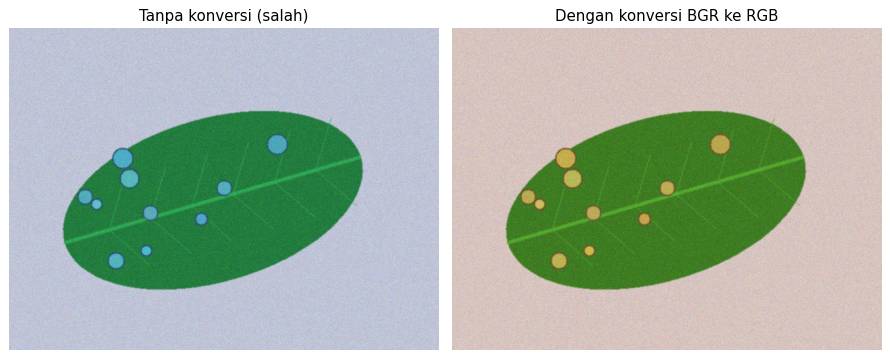

Posisi pusat bercak (y, x): (245, 227)
Potongan 5x5 nilai keabuan:
[[101  90 100  93  98]
 [108  94  99  83  96]
 [101 101 107  99 103]
 [ 93  99 102  98 102]
 [ 97  98  96  89 101]]


In [3]:

# Kode 1.1 - Uji lingkungan dan struktur larik citra

import skimage

print(
    "OpenCV:", cv2.__version__,
    "| NumPy:", np.__version__,
    "| scikit-image:", skimage.__version__
)

# Membaca citra daun teh
img = baca("../data/sintetis/citra/teh_041.png")

print("Shape:", img.shape)
print("Dtype:", img.dtype)
print("Min-maks:", img.min(), img.max())

print(
    "Piksel (y=100, x=200) dalam urutan BGR:",
    img[100, 200]
)

# Perbandingan citra BGR dan RGB
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Tanpa konversi (salah)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB")
plt.axis("off")

plt.tight_layout()
plt.savefig("../hasil/b1_bgr_rgb.png", bbox_inches="tight")
plt.show()


# Potongan 5x5 nilai keabuan di sekitar bercak
mb0 = cv2.imread(
    "../data/sintetis/mask_bercak/teh_041.png", 0
)

ys, xs = np.where(mb0 > 0)
cy, cx = int(ys.mean()), int(xs.mean())

gray0 = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

print("Posisi pusat bercak (y, x):", (cy, cx))
print("Potongan 5x5 nilai keabuan:")
print(gray0[cy-2:cy+3, cx-2:cx+3])


## **Langkah 3 — Problem Statement SIMUTEH**


Bagi petugas sortir daun teh di Kabupaten Sukabumi yang menghadapi
kesulitan dalam membedakan daun sehat dan daun yang terkena bercak
secara konsisten, terutama ketika kondisi pencahayaan tidak merata
dan bercak sulit dikenali secara visual, kami membangun SIMUTEH,
yaitu sistem pemeriksaan mutu daun teh berbasis citra yang menerima
foto daun teh dari kamera dan menghasilkan klasifikasi kondisi daun
menjadi Sehat, Bercak Ringan, dan Bercak Berat beserta persentase
luas bercak, sehingga dapat membantu proses identifikasi dan
penyortiran daun teh secara lebih terukur.


## **Langkah 4 — Diagram Pipeline SIMUTEH**

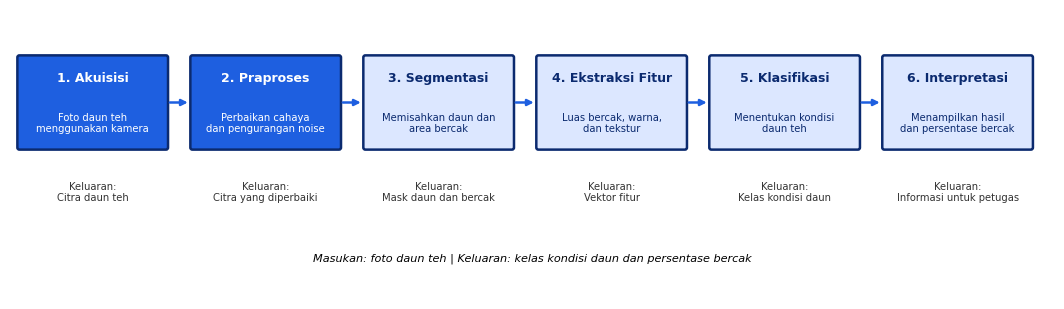

In [4]:

from matplotlib.patches import FancyBboxPatch

tahap = [
    ("1. Akuisisi",
     "Foto daun teh\nmenggunakan kamera",
     "Citra daun teh"),

    ("2. Praproses",
     "Perbaikan cahaya\ndan pengurangan noise",
     "Citra yang diperbaiki"),

    ("3. Segmentasi",
     "Memisahkan daun dan\narea bercak",
     "Mask daun dan bercak"),

    ("4. Ekstraksi Fitur",
     "Luas bercak, warna,\ndan tekstur",
     "Vektor fitur"),

    ("5. Klasifikasi",
     "Menentukan kondisi\ndaun teh",
     "Kelas kondisi daun"),

    ("6. Interpretasi",
     "Menampilkan hasil\ndan persentase bercak",
     "Informasi untuk petugas")
]

fig, ax = plt.subplots(figsize=(15, 4.2))
ax.set_xlim(0, 15)
ax.set_ylim(0, 4.2)
ax.axis("off")

for i, (nama, proses, keluaran) in enumerate(tahap):
    x = 0.15 + i * 2.48

    ax.add_patch(
        FancyBboxPatch(
            (x, 2.2), 2.1, 1.3,
            boxstyle="round,pad=0.03",
            fc="#1E5FE0" if i < 2 else "#DCE7FF",
            ec="#0B2A6F", lw=2
        )
    )

    warna = "white" if i < 2 else "#0B2A6F"

    ax.text(
        x + 1.05, 3.15, nama,
        ha="center", fontsize=10,
        weight="bold", color=warna
    )

    ax.text(
        x + 1.05, 2.55, proses,
        ha="center", va="center",
        fontsize=8, color=warna
    )

    ax.text(
        x + 1.05, 1.55,
        "Keluaran:\n" + keluaran,
        ha="center", va="center",
        fontsize=8, color="#333"
    )

    if i < 5:
        ax.annotate(
            "",
            xy=(x + 2.45, 2.85),
            xytext=(x + 2.12, 2.85),
            arrowprops=dict(
                arrowstyle="-|>",
                color="#1E5FE0", lw=2
            )
        )

ax.text(
    7.5, 0.55,
    "Masukan: foto daun teh | Keluaran: kelas kondisi daun dan persentase bercak",
    ha="center", fontsize=9, style="italic"
)

plt.savefig(
    "../hasil/b1_pipeline.png",
    bbox_inches="tight", dpi=150
)
plt.show()


## **Langkah 5 — Tabel Risiko Responsible Computer Vision**

In [5]:

risiko = pd.DataFrame([
    [
        "Privasi citra",
        "Foto daun teh dapat memuat wajah petugas atau informasi lokasi kebun.",
        "Menghindari pengambilan wajah dan menghapus metadata lokasi sebelum penyimpanan."
    ],
    [
        "Bias dan keadilan",
        "Perbedaan pencahayaan dan kualitas kamera dapat menyebabkan hasil klasifikasi tidak merata.",
        "Menggunakan variasi lima kondisi cahaya dan mengevaluasi hasil berdasarkan kondisi tersebut."
    ],
    [
        "Transparansi",
        "Petugas tidak mengetahui alasan daun dikategorikan sebagai bercak berat.",
        "Menampilkan area bercak dan persentase bercak sebagai pendukung hasil klasifikasi."
    ],
    [
        "Keamanan data",
        "Dataset dan hasil pengolahan dapat diakses oleh pihak yang tidak berwenang.",
        "Membatasi akses penyimpanan dan menjaga keamanan repository."
    ],
    [
        "Dampak sosial",
        "Kesalahan klasifikasi dapat menyebabkan daun sehat dianggap rusak atau sebaliknya.",
        "Menjadikan SIMUTEH sebagai alat bantu dan keputusan akhir tetap pada petugas."
    ],
    [
        "Keterlacakan",
        "Hasil pengolahan sulit diulang jika parameter dan versi pustaka tidak dicatat.",
        "Mencatat SEED, versi pustaka, dan parameter prapemrosesan."
    ]
], columns=[
    "Aspek",
    "Risiko pada SIMUTEH",
    "Mitigasi awal"
])

risiko.to_csv("../hasil/b1_risiko_rcv.csv", index=False)

display(risiko)


,Aspek,Risiko pada SIMUTEH,Mitigasi awal
0,Privasi citra,Foto daun teh dapat memuat wajah petugas atau ...,Menghindari pengambilan wajah dan menghapus me...
1,Bias dan keadilan,Perbedaan pencahayaan dan kualitas kamera dapa...,Menggunakan variasi lima kondisi cahaya dan me...
2,Transparansi,Petugas tidak mengetahui alasan daun dikategor...,Menampilkan area bercak dan persentase bercak ...
3,Keamanan data,Dataset dan hasil pengolahan dapat diakses ole...,Membatasi akses penyimpanan dan menjaga keaman...
4,Dampak sosial,Kesalahan klasifikasi dapat menyebabkan daun s...,Menjadikan SIMUTEH sebagai alat bantu dan kepu...
5,Keterlacakan,Hasil pengolahan sulit diulang jika parameter ...,"Mencatat SEED, versi pustaka, dan parameter pr..."


## **Langkah 6 — Jawaban pertanyaan analisis B1**


**P1.1 Semantic Gap**

Petugas sortir dapat mengenali daun teh yang memiliki bercak melalui pengamatan visual. Namun, komputer hanya menerima citra dalam bentuk kumpulan angka atau nilai piksel. Citra tersebut memiliki ukuran 480 × 640 piksel dengan tiga kanal warna BGR. Komputer tidak langsung memahami makna bercak pada daun, sehingga diperlukan proses prapemrosesan, segmentasi, ekstraksi fitur, dan klasifikasi untuk mengubah informasi visual menjadi kategori kondisi daun.

Berdasarkan hasil eksekusi kode 1.1, citra memiliki ukuran (480, 640, 3) dengan tipe data uint8 dan rentang intensitas 0–255. Nilai piksel pada koordinat (y=100, x=200) dalam urutan BGR adalah [198, 194, 223].

**P1.2 Tiga sumber variasi yang mengganggu SIMUTEH**
1. Pencahayaan: kondisi cahaya yang berbeda dapat mengubah tampilan warna daun. Ditangani pada tahap akuisisi dan prapemrosesan.
2. Skala dan jarak pengambilan gambar: jarak kamera dapat menyebabkan ukuran objek pada citra berbeda. Ditangani dengan menjaga jarak pengambilan gambar dan menggunakan persentase luas bercak.
3. Derau dan latar belakang: kualitas kamera serta tekstur alas dapat mengganggu proses identifikasi daun. Ditangani melalui penapisan dan segmentasi citra.


**P1.3 Perbedaan BGR dan RGB**

OpenCV menggunakan urutan kanal BGR, sedangkan Matplotlib menggunakan RGB. Jika citra BGR langsung ditampilkan menggunakan Matplotlib tanpa konversi, warna yang terlihat dapat menjadi tidak sesuai dengan warna aslinya. Kesalahan ini juga dapat memengaruhi ekstraksi fitur warna karena kanal yang digunakan tidak sesuai dengan interpretasi warna sebenarnya.

**P1.4 Dampak kesalahan klasifikasi**
- Daun sehat diklasifikasikan sebagai bercak berat: petani dapat dirugikan karena daun yang sebenarnya sehat dianggap memiliki mutu rendah.
- Daun bercak berat diklasifikasikan sebagai sehat: pembeli atau pihak pengolahan teh dapat dirugikan karena mutu daun tidak sesuai harapan.
Prinsip keadilan mengharuskan sistem diuji pada berbagai kondisi pencahayaan dan sumber citra. Prinsip amanah mengharuskan hasil SIMUTEH digunakan sebagai alat bantu, bukan sebagai pengganti keputusan akhir petugas sortir.

Prinsip keadilan mengharuskan sistem diuji pada berbagai kondisi pencahayaan dan sumber citra. Prinsip amanah mengharuskan hasil SIMUTEH digunakan sebagai alat bantu, bukan sebagai pengganti keputusan akhir petugas sortir.